# Yield Curve Forecasting: Dynamic Nelson–Siegel + Kalman Filter vs Transformer

ALM, exposure models, stress tests and the funding plan all need scenarios for the whole yield curve, not ten separate forecasts. Factor models deliver that, but the benchmark is brutal: at monthly frequency, yields behave almost like a random walk, and many published models fail to beat "no change". This notebook tests the classic factor models and a Transformer against that benchmark over eighteen years, strictly out of sample.

**What it does.** It forecasts the U.S. Treasury curve 1, 6 and 12 months ahead with the Dynamic Nelson–Siegel model estimated as a state-space system with the Kalman filter.

It compares this with the Diebold–Li two-step model, a Transformer neural network and the random walk, over an 18-year out-of-sample period.

**Data.** Month-end constant-maturity Treasury yields from 3 months to 20 years, 1994–2026 (FRED).

**Methods.** The Nelson–Siegel factor model (level, slope, curvature), Diebold–Li (2006) cross-sectional OLS with AR(1) factors, and the Diebold–Rudebusch–Aruoba (2006) state-space DNS with VAR(1) factors, estimated by maximum likelihood with a hand-written Kalman filter.

A small PyTorch Transformer reads 24-month curve histories. The evaluation is rolling-origin with periodic re-estimation and Diebold–Mariano tests (HAC).

**Key output.** Out-of-sample RMSE by maturity and horizon, significance against the random walk, the filtered level, slope and curvature factors, and today's 12-month curve forecast with Kalman uncertainty bands.

## 1. Why forecast the curve, and why it is hard

Curve scenarios feed ALM, PFE, stress testing and the treasury's funding plan. A risk function needs a **coherent** scenario for the whole curve, not ten independent forecasts. Factor models deliver that: three numbers (level, slope, curvature) describe 95%+ of curve moves.

The benchmark is brutal. Bond yields are close to a random walk at monthly frequency, and many published models fail to beat "no change" out of sample, especially at short horizons. A credible notebook therefore has to (i) evaluate strictly out of sample, re-estimating only with data available at each date, and (ii) test whether any improvement is **statistically** significant.

**Nelson–Siegel in factor form** (maturity $\tau$ in months, $\lambda$ the decay):

$$
y_t(\tau)=L_t+S_t\,\frac{1-e^{-\lambda\tau}}{\lambda\tau}+C_t\Big(\frac{1-e^{-\lambda\tau}}{\lambda\tau}-e^{-\lambda\tau}\Big)+\varepsilon_t(\tau)
$$

**State-space DNS** (Diebold, Rudebusch & Aruoba 2006) treats the factors as latent and estimates everything jointly:

$$
y_t=\Lambda(\lambda)f_t+\varepsilon_t,\quad \varepsilon_t\sim N(0,R),\qquad f_t-\mu=A\,(f_{t-1}-\mu)+\eta_t,\quad \eta_t\sim N(0,Q),
$$

with $R$ diagonal (a measurement error per maturity) and $A$, $Q$ full. The Kalman filter gives the likelihood, the filtered factors, and **forecast covariances**, so uncertainty bands come for free.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
from scipy.optimize import minimize
from scipy.stats import norm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SERIES = {
    "DGS3MO": 3,
    "DGS6MO": 6,
    "DGS1": 12,
    "DGS2": 24,
    "DGS3": 36,
    "DGS5": 60,
    "DGS7": 84,
    "DGS10": 120,
    "DGS20": 240,
}
START = "1994-01-01"  # 20-year CMT resumes in October 1993
OOS_START = "2008-01-31"  # first forecast origin
HORIZONS = [1, 6, 12]  # months
# months between re-estimations (expanding window)
REFIT_EVERY = 36
LAMBDA_DL = 0.0609  # Diebold–Li decay for maturities in months
SEQ_LEN = 24  # months of history the Transformer sees
SEED = 17
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

print(f"torch {torch.__version__} · run on {dt.date.today():%Y-%m-%d}")

torch 2.14.1+cu130 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "Random walk": INK_2,
    "Diebold-Li (2-step)": PALETTE[3],
    "DNS Kalman": PALETTE[0],
    "Transformer": PALETTE[1],
}

## 3. Data

In [3]:
def fetch_cmt():
    frames = [
        pd.DataFrame({"date": s.index, "tau": tau, "y": s.values})
        for sid, tau in SERIES.items()
        for s in [fred.get_series(sid, observation_start=START).dropna()]
    ]
    return pd.concat(frames, ignore_index=True)


daily = (
    cached("fred_cmt_daily", fetch_cmt)
    .pivot(index="date", columns="tau", values="y")
    .sort_index()
)
daily = daily[daily.index < pd.Timestamp.today().normalize()]
monthly = daily.resample("ME").last().dropna()
TAUS = monthly.columns.to_numpy(dtype=float)
Y = monthly.to_numpy()
DATES = monthly.index
print(
    f"{len(monthly)} month-end curves · {DATES.min():%Y-%m} →"
    f" {DATES.max():%Y-%m} (last row = latest available day,"
    f" {daily.index.max():%d %b %Y}) · maturities (months)"
    f" {', '.join(str(int(t)) for t in TAUS)}"
)
monthly.tail(3).round(2)

394 month-end curves · 1994-01 → 2026-10 (last row = latest available day, 15 Oct 2026) · maturities (months) 3, 6, 12, 24, 36, 60, 84, 120, 240


tau,3,6,12,24,36,60,84,120,240
date,,,,,,,,,
2026-08-31,3.91,3.99,4.16,4.34,4.40,4.49,4.62,4.75,5.24
2026-09-30,4.20,4.33,4.54,4.88,5.00,5.09,5.19,5.29,5.68
2026-10-31,4.28,4.35,4.49,4.77,4.85,4.91,5.00,5.10,5.48


## 4. Diebold–Li: factors by cross-sectional OLS

With $\lambda$ fixed, each month's curve gives level, slope and curvature by OLS. These factors are the classic interpretable summary: level ≈ long yield, slope ≈ −(10y − 3m), curvature ≈ the belly relative to the wings.

Nelson–Siegel cross-sectional fit: RMSE 9.5 bp across all months and maturities


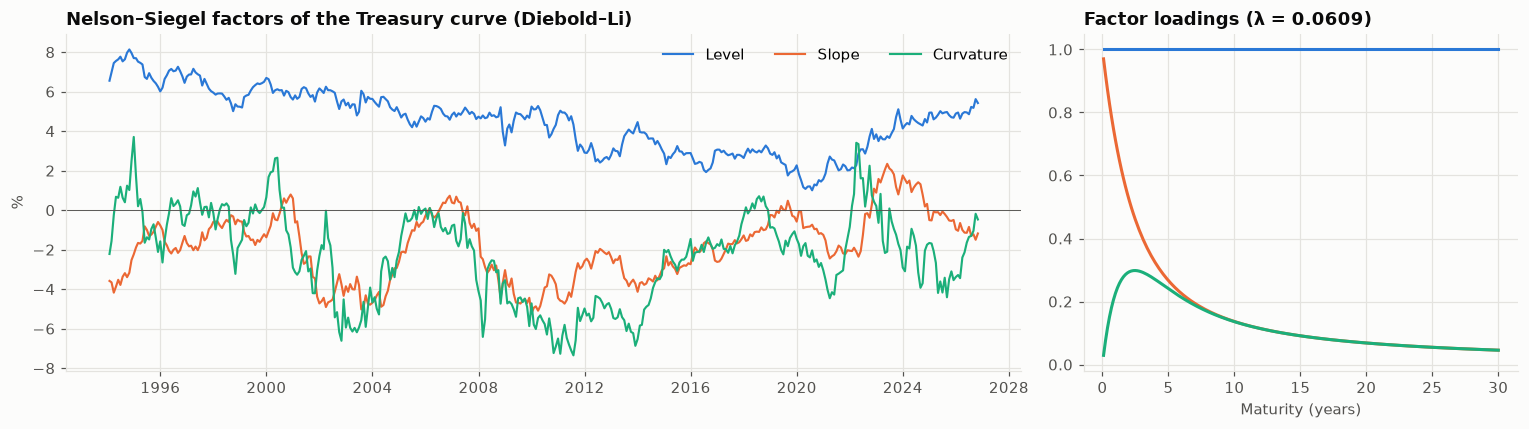

In [4]:
def ns_loadings(lam, taus=TAUS):
    x = lam * taus
    f1 = (1 - np.exp(-x)) / x
    return np.column_stack([np.ones_like(taus), f1, f1 - np.exp(-x)])


LOAD_DL = ns_loadings(LAMBDA_DL)
# months × 3
F_DL = np.linalg.lstsq(LOAD_DL, Y.T, rcond=None)[0].T
fit_rmse = np.sqrt(np.mean((Y - F_DL @ LOAD_DL.T) ** 2)) * 100
print(
    f"Nelson–Siegel cross-sectional fit: RMSE {fit_rmse:.1f} bp across all"
    " months and maturities"
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]}
)
ax = axes[0]
for k, (name, color) in enumerate(
    zip(["Level", "Slope", "Curvature"], PALETTE)
):
    ax.plot(DATES, F_DL[:, k], color=color, lw=1.4, label=name)
ax.axhline(0, color=INK_2, lw=0.6)
ax.set_title("Nelson–Siegel factors of the Treasury curve (Diebold–Li)")
ax.set_ylabel("%")
ax.legend(ncol=3)
ax = axes[1]
tt = np.linspace(1, 360, 200)
for k, (name, color) in enumerate(
    zip(["Level", "Slope", "Curvature"], PALETTE)
):
    ax.plot(tt / 12, ns_loadings(LAMBDA_DL, tt)[:, k], color=color, label=name)
ax.set_title(f"Factor loadings (λ = {LAMBDA_DL})")
ax.set_xlabel("Maturity (years)")
plt.tight_layout()
save_fig(fig, "01_ns_factors_and_loadings")
plt.show()

## 5. DNS as a state-space model: Kalman filter and maximum likelihood

The filter is written out in a few lines of NumPy (for filtering and forecasting) and mirrored in PyTorch, so that the optimiser gets the exact gradient of the log-likelihood by automatic differentiation instead of 28 finite differences. Parameters are $\mu$ (3), $A$ (9), the Cholesky factor of $Q$ (6), $\log$ measurement s.d.

(9) and $\log\lambda$: 28 in total, estimated by L-BFGS from Diebold–Li starting values. $A$ is shrunk toward stationarity if the optimiser wanders (eigenvalues capped at 0.995).

In [5]:
def unpack(theta):
    mu, A = theta[:3], theta[3:12].reshape(3, 3)
    L = np.zeros((3, 3))
    L[np.tril_indices(3)] = theta[12:18]
    R = np.diag(np.exp(2 * theta[18:27]))
    lam = np.exp(theta[27])
    return mu, A, L @ L.T + 1e-8 * np.eye(3), R, lam


def kalman(theta, Yobs, return_states=False):
    mu, A, Q, R, lam = unpack(theta)
    if np.max(np.abs(np.linalg.eigvals(A))) > 0.995:
        return (1e10, None) if return_states else 1e10
    Lmb = ns_loadings(lam)
    f, P = mu.copy(), np.eye(3) * 4.0
    ll, states, covs = 0.0, [], []
    for y in Yobs:
        f_pred = mu + A @ (f - mu)
        P_pred = A @ P @ A.T + Q
        v = y - Lmb @ f_pred
        Fm = Lmb @ P_pred @ Lmb.T + R
        Fi = np.linalg.inv(Fm)
        K = P_pred @ Lmb.T @ Fi
        f = f_pred + K @ v
        P = (np.eye(3) - K @ Lmb) @ P_pred
        ll += -0.5 * (
            np.linalg.slogdet(Fm)[1] + v @ Fi @ v + len(y) * np.log(2 * np.pi)
        )
        if return_states:
            states.append(f.copy())
            covs.append(P.copy())
    if return_states:
        return -ll, (np.array(states), np.array(covs))
    return -ll


def start_values(F, Yobs):
    X0, X1 = F[:-1], F[1:]
    mu = F.mean(axis=0)
    A = np.linalg.lstsq(X0 - mu, X1 - mu, rcond=None)[0].T
    resid = (X1 - mu) - (X0 - mu) @ A.T
    L = np.linalg.cholesky(np.cov(resid.T) + 1e-6 * np.eye(3))
    meas = np.log(np.maximum((Yobs - F @ LOAD_DL.T).std(axis=0), 0.02))
    return np.r_[mu, A.ravel(), L[np.tril_indices(3)], meas, np.log(LAMBDA_DL)]


def kalman_nll_torch(theta_np, Yobs):
    """
    Same filter in PyTorch, so the exact gradient of the likelihood comes from
    one backward pass.
    """
    th = torch.tensor(theta_np, dtype=torch.float64, requires_grad=True)
    mu, A = th[:3], th[3:12].reshape(3, 3)
    L = torch.zeros(3, 3, dtype=torch.float64)
    L = L.index_put(
        tuple(torch.as_tensor(np.array(np.tril_indices(3)))), th[12:18]
    )
    Q = L @ L.T + 1e-8 * torch.eye(3, dtype=torch.float64)
    R = torch.diag(torch.exp(2 * th[18:27]))
    lam = torch.exp(th[27])
    tau = torch.tensor(TAUS, dtype=torch.float64)
    x = lam * tau
    f1 = (1 - torch.exp(-x)) / x
    Lmb = torch.stack([torch.ones_like(tau), f1, f1 - torch.exp(-x)], dim=1)
    Yt = torch.tensor(Yobs, dtype=torch.float64)
    f, P = mu.clone(), torch.eye(3, dtype=torch.float64) * 4.0
    nll = torch.zeros((), dtype=torch.float64)
    I3 = torch.eye(3, dtype=torch.float64)
    for y in Yt:
        f_pred = mu + A @ (f - mu)
        P_pred = A @ P @ A.T + Q
        v = y - Lmb @ f_pred
        Fm = Lmb @ P_pred @ Lmb.T + R
        Fi = torch.linalg.inv(
            Fm + 1e-10 * torch.eye(len(TAUS), dtype=torch.float64)
        )
        K = P_pred @ Lmb.T @ Fi
        f = f_pred + K @ v
        P = (I3 - K @ Lmb) @ P_pred
        nll = nll + 0.5 * (
            torch.logdet(Fm) + v @ Fi @ v + len(TAUS) * np.log(2 * np.pi)
        )
    if np.max(np.abs(np.linalg.eigvals(A.detach().numpy()))) > 0.995:
        return 1e10, np.zeros_like(theta_np)
    nll.backward()
    return nll.item(), th.grad.numpy()


def fit_dns(Yobs, F_start, th0=None):
    th0 = start_values(F_start, Yobs) if th0 is None else th0
    bounds = (
        [(-5, 20)] * 3
        + [(-1.5, 1.5)] * 9
        + [(-3, 3)] * 6
        # measurement s.d. ≥ 0.2 bp
        + [(np.log(0.002), np.log(1.0))] * 9
        + [(np.log(0.01), np.log(0.5))]
    )
    th0 = np.clip(th0, [b[0] for b in bounds], [b[1] for b in bounds])
    res = minimize(
        kalman_nll_torch,
        th0,
        args=(Yobs,),
        jac=True,
        method="L-BFGS-B",
        bounds=bounds,
        options={"maxiter": 300},
    )
    return res.x, res


t0 = time.perf_counter()
theta_full, res_full = fit_dns(Y, F_DL)
mu_f, A_f, Q_f, R_f, lam_f = unpack(theta_full)
_, (F_KF, P_KF) = kalman(theta_full, Y, return_states=True)
print(
    f"Full-sample DNS MLE in {time.perf_counter() - t0:.0f}s · log-likelihood"
    f" {-res_full.fun:,.1f} · λ = {lam_f:.4f} (peak curvature loading at"
    f" {1.793 / lam_f / 12:.1f} years)"
)
display(
    pd.DataFrame(
        A_f, index=["L", "S", "C"], columns=["L(t-1)", "S(t-1)", "C(t-1)"]
    ).round(3)
)
pd.Series(
    np.sqrt(np.diag(R_f)) * 100,
    index=[f"{int(t)}m" for t in TAUS],
    name="measurement s.d. (bp)",
).round(1).to_frame().T

Full-sample DNS MLE in 98s · log-likelihood 2,682.0 · λ = 0.0464 (peak curvature loading at 3.2 years)


,L(t-1),S(t-1),C(t-1)
L,0.98,0.01,0.01
S,-0.01,0.95,0.05
C,0.01,0.01,0.93


,3m,6m,12m,24m,36m,60m,84m,120m,240m
measurement s.d. (bp),15.10,0.20,7.40,5.70,0.20,5.00,2.70,9.50,26.30


## 6. A Transformer on curve histories

The neural benchmark sees the last 24 month-end curves (9 yields each, standardised) and predicts the **change** in every yield 1, 6 and 12 months ahead: 27 outputs from one model. Its architecture is a linear embedding of each month, learned positional embeddings, 2 encoder layers with 4 heads, and mean pooling.

Predicting changes rather than levels builds the random walk in as the zero prediction, a strong prior. With roughly 160–380 training sequences per refit, the model is small (≈25k parameters) and ensembled over 3 seeds with early stopping on the last 15% of each training window.

In [6]:
class CurveTransformer(torch.nn.Module):
    def __init__(self, n_in, n_out, d=32):
        super().__init__()
        self.inp = torch.nn.Linear(n_in, d)
        self.pos = torch.nn.Parameter(torch.zeros(1, SEQ_LEN, d))
        layer = torch.nn.TransformerEncoderLayer(
            d, nhead=4, dim_feedforward=64, dropout=0.1, batch_first=True
        )
        self.enc = torch.nn.TransformerEncoder(
            layer, num_layers=2, enable_nested_tensor=False
        )
        self.out = torch.nn.Linear(d, n_out)

    def forward(self, x):
        return self.out(self.enc(self.inp(x) + self.pos).mean(dim=1))


def make_sequences(Yarr, end):
    """
    Inputs ending at t (t < end − max horizon) and their 1/6/12-month yield
    changes.
    """
    Xs, Ys = [], []
    for t in range(SEQ_LEN - 1, end - max(HORIZONS)):
        Xs.append(Yarr[t - SEQ_LEN + 1 : t + 1])
        Ys.append(np.concatenate([Yarr[t + h] - Yarr[t] for h in HORIZONS]))
    return np.array(Xs), np.array(Ys)


def fit_transformer(Yarr, end, seeds=3, epochs=300):
    Xs, Ys = make_sequences(Yarr, end)
    m, s = Yarr[:end].mean(axis=0), Yarr[:end].std(axis=0)
    ys = Ys.std(axis=0) + 1e-6
    Xt = torch.tensor((Xs - m) / s, dtype=torch.float32)
    Yt = torch.tensor(Ys / ys, dtype=torch.float32)
    n_val = max(12, int(0.15 * len(Xt)))
    models = []
    for k in range(seeds):
        torch.manual_seed(SEED + k)
        net = CurveTransformer(Yarr.shape[1], Ys.shape[1])
        opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-2)
        best, best_state, patience = np.inf, None, 0
        for ep in range(epochs):
            net.train()
            for b in torch.randperm(len(Xt) - n_val).split(32):
                loss = torch.mean((net(Xt[b]) - Yt[b]) ** 2)
                opt.zero_grad()
                loss.backward()
                opt.step()
            net.eval()
            with torch.no_grad():
                val = torch.mean((net(Xt[-n_val:]) - Yt[-n_val:]) ** 2).item()
            if val < best - 1e-4:
                best, best_state, patience = (
                    val,
                    {k_: v.clone() for k_, v in net.state_dict().items()},
                    0,
                )
            else:
                patience += 1
                if patience > 25:
                    break
        net.load_state_dict(best_state)
        models.append(net)

    def predict(window):
        x = torch.tensor(((window - m) / s)[None], dtype=torch.float32)
        with torch.no_grad():
            out = (
                torch.stack([mm(x) for mm in models]).mean(0).numpy().ravel()
                * ys
            )
        return {
            h: out[i * len(TAUS) : (i + 1) * len(TAUS)]
            for i, h in enumerate(HORIZONS)
        }

    return predict

## 7. Rolling-origin out-of-sample evaluation, 2008–2026

At every month-end origin from January 2008, each model forecasts the curve 1, 6 and 12 months ahead using **only data up to that origin**. Models are re-estimated on an expanding window every 36 months; between re-estimations the Kalman filter and the Diebold–Li factors are simply updated with each new curve. This is the "estimate rarely, update often" practice of a real forecasting process.

In [7]:
def dl_forecast(F_hist, h):
    """Diebold–Li: AR(1) on each factor, iterated h steps."""
    out = []
    for k in range(3):
        x0, x1 = F_hist[:-1, k], F_hist[1:, k]
        c, phi = np.polyfit(x0, x1, 1)[::-1]
        f = F_hist[-1, k]
        for _ in range(h):
            f = c + phi * f
        out.append(f)
    return LOAD_DL @ np.array(out)


def dns_forecast(theta, f_T, P_T, h):
    mu, A, Q, R, lam = unpack(theta)
    Lmb = ns_loadings(lam)
    Ah = np.linalg.matrix_power(A, h)
    f_h = mu + Ah @ (f_T - mu)
    P_h = Ah @ P_T @ Ah.T + sum(
        np.linalg.matrix_power(A, j) @ Q @ np.linalg.matrix_power(A, j).T
        for j in range(h)
    )
    return Lmb @ f_h, np.sqrt(np.diag(Lmb @ P_h @ Lmb.T + R))


origins = np.flatnonzero(DATES >= pd.Timestamp(OOS_START))
fc = {(m, h): {} for m in MODEL_COLORS for h in HORIZONS}
t0 = time.perf_counter()
theta, tf_predict, last_fit = None, None, None
for t in origins:
    if last_fit is None or t - last_fit >= REFIT_EVERY:
        F_est = np.linalg.lstsq(LOAD_DL, Y[: t + 1].T, rcond=None)[0].T
        # warm start from the previous estimate
        theta, _ = fit_dns(Y[: t + 1], F_est, th0=theta)
        tf_predict = fit_transformer(Y, t + 1)
        last_fit = t
    _, (states, covs) = kalman(theta, Y[: t + 1], return_states=True)
    F_hist = np.linalg.lstsq(LOAD_DL, Y[: t + 1].T, rcond=None)[0].T
    tf = tf_predict(Y[t - SEQ_LEN + 1 : t + 1])
    for h in HORIZONS:
        if t + h >= len(Y):
            continue
        fc[("Random walk", h)][t] = Y[t]
        fc[("Diebold-Li (2-step)", h)][t] = dl_forecast(F_hist, h)
        fc[("DNS Kalman", h)][t] = dns_forecast(
            theta, states[-1], covs[-1], h
        )[0]
        fc[("Transformer", h)][t] = Y[t] + tf[h]
print(
    f"{len(origins)} forecast origins with"
    f" {len(range(origins[0], origins[-1] + 1, REFIT_EVERY))} re-estimations"
    f" in {time.perf_counter() - t0:.0f}s"
)

226 forecast origins with 7 re-estimations in 323s


In [8]:
def newey_west_var(d, lag):
    d = d - d.mean()
    v = np.mean(d * d)
    for k in range(1, lag + 1):
        v += 2 * (1 - k / (lag + 1)) * np.mean(d[k:] * d[:-k])
    return v / len(d)


rows, errs = [], {}
for h in HORIZONS:
    ts = sorted(fc[("Random walk", h)])
    actual = np.array([Y[t + h] for t in ts])
    rw_err = actual - np.array([fc[("Random walk", h)][t] for t in ts])
    for m in MODEL_COLORS:
        e = actual - np.array([fc[(m, h)][t] for t in ts])
        errs[(m, h)] = e
        # loss differential vs RW, pooled over maturities
        d = (rw_err**2).mean(axis=1) - (e**2).mean(axis=1)
        dm = (
            d.mean() / np.sqrt(newey_west_var(d, max(h - 1, 1)))
            if m != "Random walk"
            else np.nan
        )
        rows.append({
            "horizon (m)": h,
            "model": m,
            "RMSE all maturities (bp)": np.sqrt(np.mean(e**2)) * 100,
            "RMSE 3m (bp)": np.sqrt(np.mean(e[:, 0] ** 2)) * 100,
            "RMSE 2y (bp)": np.sqrt(np.mean(e[:, 3] ** 2)) * 100,
            "RMSE 10y (bp)": np.sqrt(np.mean(e[:, 7] ** 2)) * 100,
            "relative to RW": np.sqrt(np.mean(e**2)) / np.sqrt(
                np.mean(rw_err**2)
            ),
            "DM stat vs RW": dm,
            "DM p-value": (
                2 * (1 - norm.cdf(abs(dm))) if m != "Random walk" else np.nan
            ),
        })
league = pd.DataFrame(rows).set_index(["horizon (m)", "model"])
league.round(3)

RMSE all maturities (bp)  RMSE 3m (bp)  \
horizon (m) model                                                         
1           Random walk                             22.37         17.66   
            Diebold-Li (2-step)                     24.96         21.33   
            DNS Kalman                              25.18         20.66   
            Transformer                             23.11         18.68   
6           Random walk                             66.25         71.87   
            Diebold-Li (2-step)                     73.34         78.87   
            DNS Kalman                              68.53         68.45   
            Transformer                             71.89         75.27   
12          Random walk                            103.08        123.66   
            Diebold-Li (2-step)                    115.21        132.77   
            DNS Kalman                             103.84        108.60   
            Transformer                            113.19        133.55   

                                 RMSE 2y (bp)  RMSE 10y (bp)  relative to RW  \
horizon (m) model                                                              
1           Random walk                 21.86          25.29            1.00   
            Diebold-Li (2-step)         23.79          25.49            1.12   
            DNS Kalman                  22.77          26.90            1.12   
            Transformer                 23.23          25.58            1.03   
6           Random walk                 66.20          62.50            1.00   
            Diebold-Li (2-step)         74.47          65.55            1.11   
            DNS Kalman                  67.34          67.33            1.03   
            Transformer                 77.11          65.13            1.08   
12          Random walk                106.83          84.25            1.00   
            Diebold-Li (2-step)        120.93          93.83            1.12   
            DNS Kalman                 106.55          95.47            1.01   
            Transformer                123.73          92.84            1.10   

                                 DM stat vs RW  DM p-value  
horizon (m) model                                           
1           Random walk                    NaN         NaN  
            Diebold-Li (2-step)          -6.97        0.00  
            DNS Kalman                   -5.98        0.00  
            Transformer                  -2.72        0.01  
6           Random walk                    NaN         NaN  
            Diebold-Li (2-step)          -2.95        0.00  
            DNS Kalman                   -0.46        0.65  
            Transformer                  -1.69        0.09  
12          Random walk                    NaN         NaN  
            Diebold-Li (2-step)          -1.89        0.06  
            DNS Kalman                   -0.08        0.93  
            Transformer                  -1.82        0.07

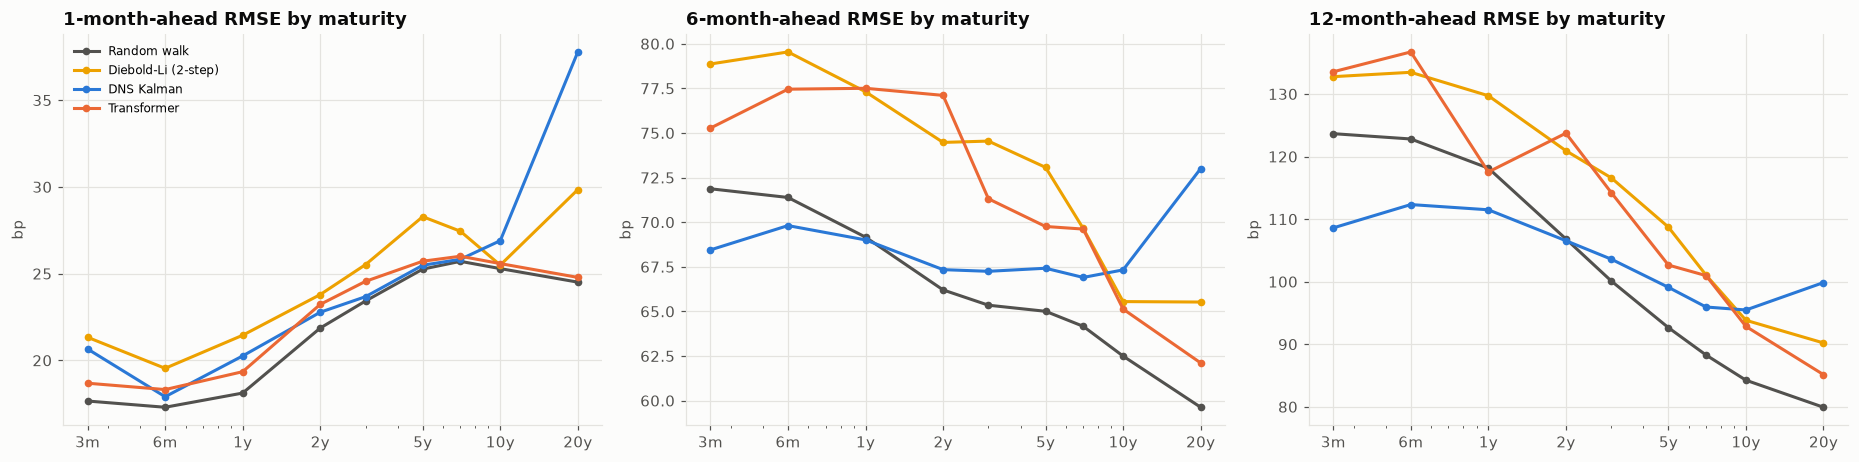

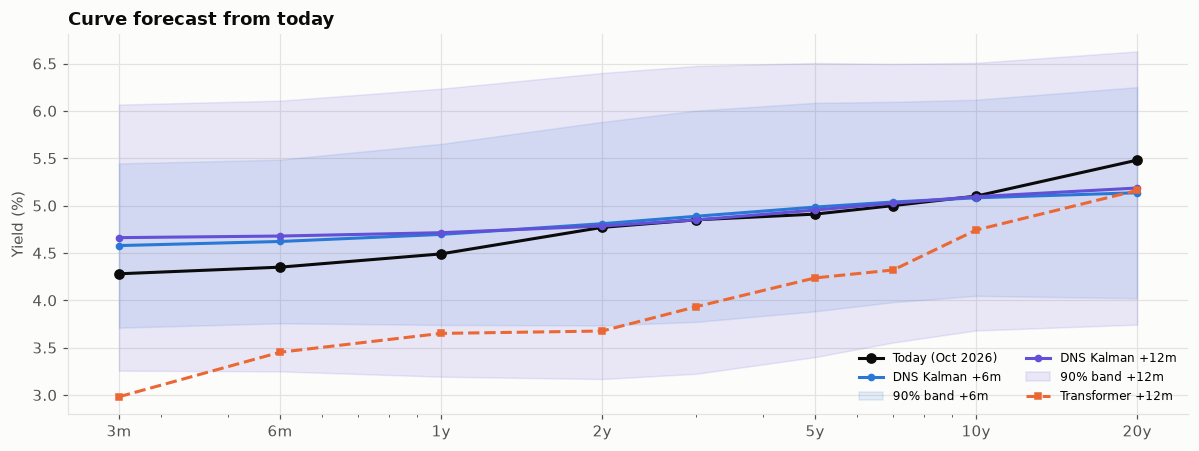

In [9]:
# --- Chart 2: RMSE by maturity and horizon; Chart 3: today's forecast
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=False)
for ax, h in zip(axes, HORIZONS):
    for m, color in MODEL_COLORS.items():
        ax.plot(
            TAUS / 12,
            np.sqrt(np.mean(errs[(m, h)] ** 2, axis=0)) * 100,
            "o-",
            color=color,
            ms=4,
            label=m,
        )
    ax.set_xscale("log")
    ax.set_xticks(
        [0.25, 0.5, 1, 2, 5, 10, 20],
        ["3m", "6m", "1y", "2y", "5y", "10y", "20y"],
    )
    ax.set_title(f"{h}-month-ahead RMSE by maturity")
    ax.set_ylabel("bp")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "02_oos_rmse_by_maturity")
plt.show()

# Today's 12-month forecast from the full-sample DNS with Kalman bands, and the
# Transformer refitted on all data
t_last = len(Y) - 1
tf_now = fit_transformer(Y, len(Y))(Y[-SEQ_LEN:])
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(TAUS / 12, Y[-1], "o-", color=INK, label=f"Today ({DATES[-1]:%b %Y})")
for h, color in zip([6, 12], [PALETTE[0], PALETTE[6]]):
    mean, sd = dns_forecast(theta_full, F_KF[-1], P_KF[-1], h)
    ax.plot(
        TAUS / 12, mean, "o-", color=color, ms=4, label=f"DNS Kalman +{h}m"
    )
    ax.fill_between(
        TAUS / 12,
        mean - 1.645 * sd,
        mean + 1.645 * sd,
        color=color,
        alpha=0.12,
        label=f"90% band +{h}m",
    )
ax.plot(
    TAUS / 12,
    Y[-1] + tf_now[12],
    "s--",
    color=PALETTE[1],
    ms=4,
    label="Transformer +12m",
)
ax.set_xscale("log")
ax.set_xticks(
    [0.25, 0.5, 1, 2, 5, 10, 20], ["3m", "6m", "1y", "2y", "5y", "10y", "20y"]
)
ax.set_title("Curve forecast from today")
ax.set_ylabel("Yield (%)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
save_fig(fig, "03_forecast_from_today")
plt.show()
league.to_csv(OUT_DIR / "oos_forecast_league.csv")
pd.DataFrame(
    F_KF, index=DATES, columns=["level", "slope", "curvature"]
).to_csv(OUT_DIR / "dns_kalman_factors.csv")
pd.DataFrame(
    {
        f"+{h}m": dns_forecast(theta_full, F_KF[-1], P_KF[-1], h)[0]
        for h in HORIZONS
    },
    index=[f"{int(t)}m" for t in TAUS],
).to_csv(OUT_DIR / "dns_forecast_today.csv")

## 8. Reading the results and limitations

Out-of-sample, January 2008 to October 2026 (226 origins, 7 re-estimations):

- **The random walk is very hard to beat, as the literature warns.** No model beats "no change" with statistical significance at any horizon.
  - At **1 month** every model is significantly *worse* than the random walk (DM p < 0.01). One month of factor mean-reversion is mostly noise.
  - At **6 and 12 months** the **DNS Kalman** model is statistically indistinguishable from the random walk (RMSE ratio 1.03 and 1.01, DM p 0.65 and 0.93).
  - DNS Kalman is **better at the short end** at 12 months (3-month yield RMSE 109 bp vs 124 bp), because policy-rate cycles mean-revert. It is worse at 10–20 years.
- **The two-step Diebold–Li model is 11–12% above the random walk at every horizon** and is the worst at 6 and 12 months. Estimating the factor dynamics separately from the measurement equation throws away information that the Kalman filter uses.
- **The Transformer** sits between the two (3–10% above the random walk). It is close to the random walk at 1 month, where predicting changes makes "no change" its natural default, but it does not learn useful dynamics from about 200–380 overlapping training sequences.

**A structural point for curve users:** the 20-year CMT sits about 40 bp above what a three-factor Nelson–Siegel curve can produce (the 20-year "hump" since the bond's 2020 reissue). DNS therefore starts its forecasts from the smoothed 20-year value, which explains its largest maturity error (measurement s.d. 26 bp). The Kalman model's strength is the **coherent scenario with uncertainty bands**, as in the chart from today, not point accuracy.

**Today's forecasts disagree.** DNS projects a mildly higher, flatter curve within wide 90% bands (±100–150 bp at 12 months). The Transformer projects the 3-month yield about 130 bp lower in a year, at the edge of the DNS band. Given its 12-month record (10% worse than the random walk), that is a scenario to stress, not a forecast to act on.

**Limitations**

- One curve, one country, monthly frequency. Daily data or macro factors (inflation, activity, the policy rate path; "yields-macro" models) are the standard extensions.
- The DNS model is not arbitrage-free. The arbitrage-free version (AFNS, Christensen–Diebold–Rudebusch) adds a small convexity term that matters at the long end.
- Re-estimation every 36 months is a compute compromise. Monthly re-estimation changes RMSEs by a few tenths of a bp in tests of this kind, but not the ranking.
- The Transformer's input is the curve alone, and the sample is small for a neural network. That is the honest setting: nothing is gained by giving the network data the factor models do not see.

## References

### Finance and regulation

- Diebold, F. X., & Li, C. (2006). Forecasting the term structure of government bond yields. *Journal of Econometrics, 130*(2), 337–364. https://doi.org/10.1016/j.jeconom.2005.03.005
- Diebold, F. X., Rudebusch, G. D., & Aruoba, S. B. (2006). The macroeconomy and the yield curve: A dynamic latent factor approach. *Journal of Econometrics, 131*(1–2), 309–338. https://doi.org/10.1016/j.jeconom.2005.01.011
- Nelson, C. R., & Siegel, A. F. (1987). Parsimonious modeling of yield curves. *The Journal of Business, 60*(4), 473–489. https://doi.org/10.1086/296409
- Duffee, G. R. (2002). Term premia and interest rate forecasts in affine models. *The Journal of Finance, 57*(1), 405–443. https://doi.org/10.1111/1540-6261.00426
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263. https://doi.org/10.1080/07350015.1995.10524599

### Machine learning and deep learning

- Kalman, R. E. (1960). A new approach to linear filtering and prediction problems. *Journal of Basic Engineering, 82*(1), 35–45. https://doi.org/10.1115/1.3662552
- Durbin, J., & Koopman, S. J. (2012). *Time series analysis by state space methods* (2nd ed.). Oxford University Press. https://doi.org/10.1093/acprof:oso/9780199641178.001.0001
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1706.03762